In [1]:
# Assignment 1: ML Model for Car Mileage Estimation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv(
    r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-1-ML-Model-for-Car-Mileage-Estimation\auto-mpg.csv"
)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of rows: 398
Number of columns: 9

Column Names:
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin', 'car name']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(3), int64(4), str(2)
memory usage: 28.1 KB


In [5]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [8]:
print("Non-numeric horsepower values:")
print(
    df[
        ~df["horsepower"]
        .str.replace(".", "", regex=False)
        .str.isnumeric()
    ]["horsepower"].unique()
)

Non-numeric horsepower values:
<StringArray>
['?']
Length: 1, dtype: str


In [9]:
df["horsepower"] = pd.to_numeric(
    df["horsepower"],
    errors="coerce"
)

print("Missing horsepower values after conversion:")
print(df["horsepower"].isnull().sum())

Missing horsepower values after conversion:
6


In [10]:
df["horsepower"] = df["horsepower"].fillna(
    df["horsepower"].median()
)

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [11]:
print(df.dtypes)

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model year        int64
origin            int64
car name            str
dtype: object


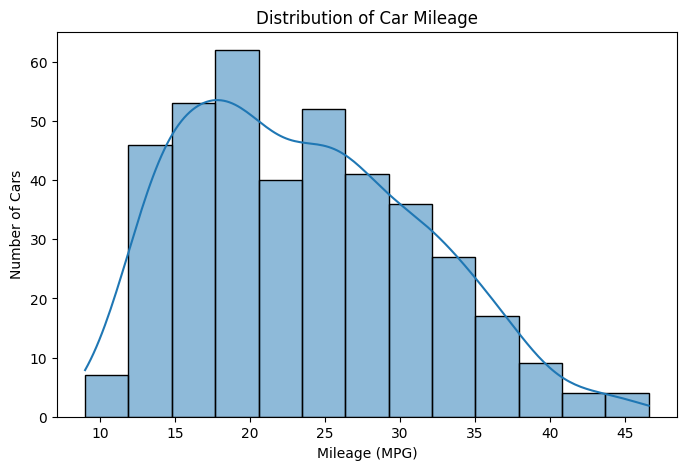

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["mpg"],
    kde=True
)

plt.title("Distribution of Car Mileage")
plt.xlabel("Mileage (MPG)")
plt.ylabel("Number of Cars")
plt.show()

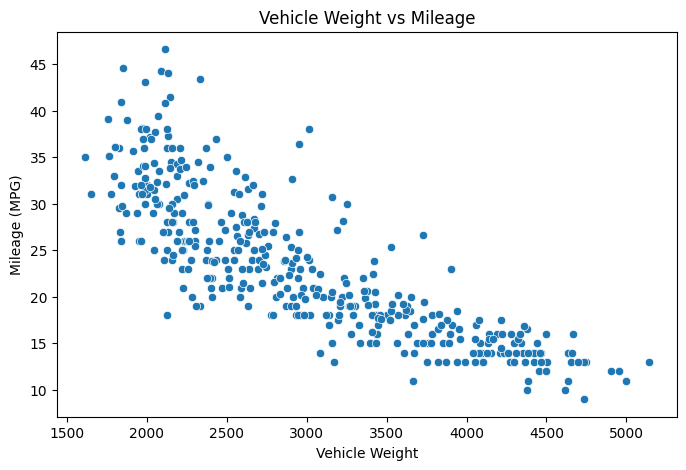

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="weight",
    y="mpg"
)

plt.title("Vehicle Weight vs Mileage")
plt.xlabel("Vehicle Weight")
plt.ylabel("Mileage (MPG)")
plt.show()

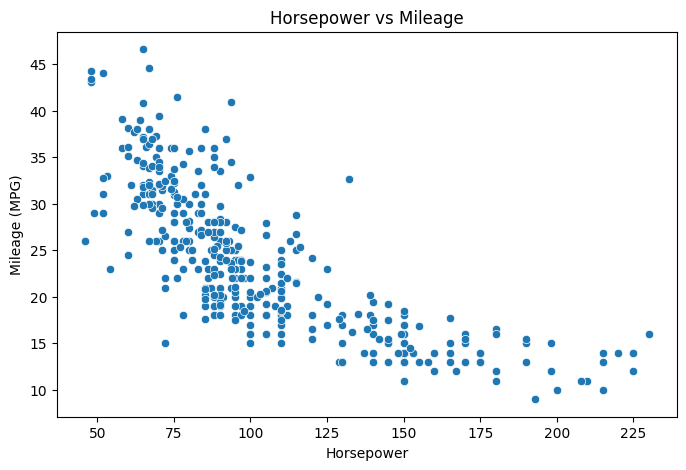

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="horsepower",
    y="mpg"
)

plt.title("Horsepower vs Mileage")
plt.xlabel("Horsepower")
plt.ylabel("Mileage (MPG)")
plt.show()

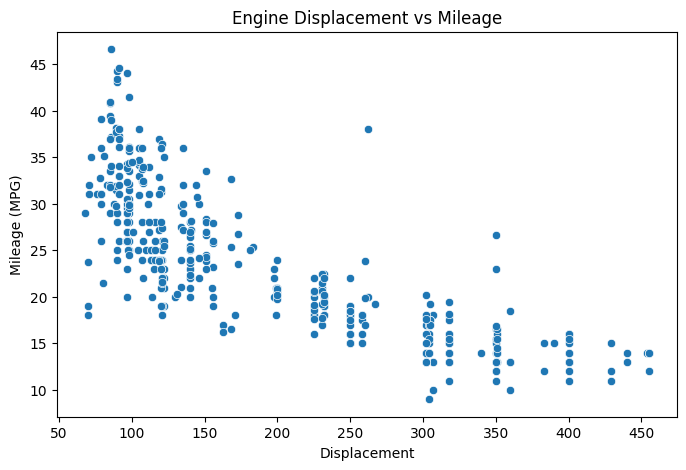

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="displacement",
    y="mpg"
)

plt.title("Engine Displacement vs Mileage")
plt.xlabel("Displacement")
plt.ylabel("Mileage (MPG)")
plt.show()

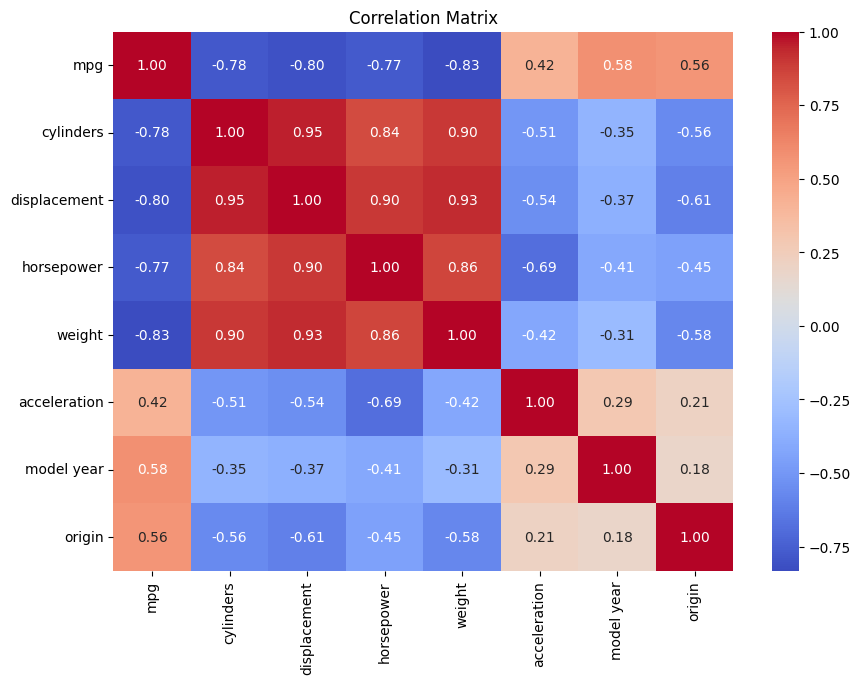

In [16]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [17]:
features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model year",
    "origin"
]

X = df[features]
y = df["mpg"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   cylinders  displacement  horsepower  weight  acceleration  model year  \
0          8         307.0       130.0    3504          12.0          70   
1          8         350.0       165.0    3693          11.5          70   
2          8         318.0       150.0    3436          11.0          70   
3          8         304.0       150.0    3433          12.0          70   
4          8         302.0       140.0    3449          10.5          70   

   origin  
0       1  
1       1  
2       1  
3       1  
4       1  

Target:
0    18.0
1    15.0
2    18.0
3    16.0
4    17.0
Name: mpg, dtype: float64


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 318
Testing samples: 80


In [19]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [20]:
y_pred = model.predict(X_test)

print("First 10 predicted values:")
print(y_pred[:10])

First 10 predicted values:
[32.88140046 29.55780381 21.36955005 16.79734409 12.4982001  27.20579297
 27.90034172  9.77551057 16.88434148 22.03432001]


In [21]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-------------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.2f}")

Model Evaluation
-------------------------
MAE  : 2.26
RMSE : 2.86
R²   : 0.85


In [22]:
comparison = pd.DataFrame({
    "Actual MPG": y_test.values,
    "Predicted MPG": y_pred
})

comparison.head(10)

,Actual MPG,Predicted MPG
0,33.0,32.881400
1,28.0,29.557804
2,19.0,21.369550
3,13.0,16.797344
4,14.0,12.498200
5,27.0,27.205793
6,24.0,27.900342
7,13.0,9.775511
8,17.0,16.884341
9,21.0,22.034320


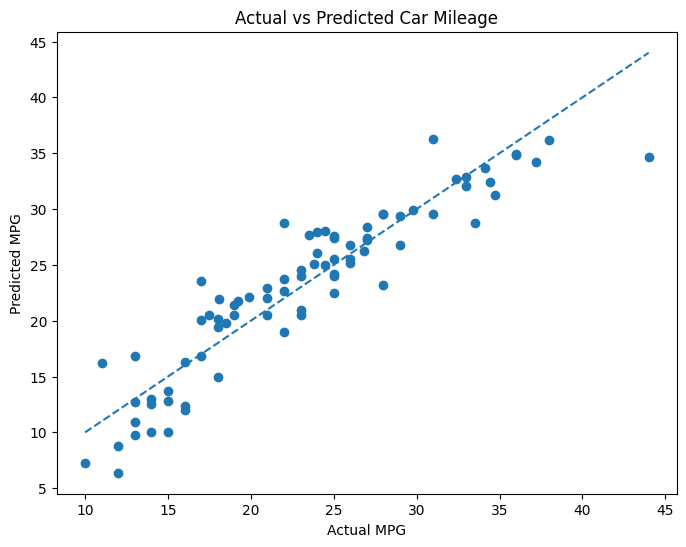

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted Car Mileage")

plt.show()

In [24]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

,Feature,Coefficient
6,origin,1.322959
5,model year,0.794960
4,acceleration,0.068776
1,displacement,0.014220
3,weight,-0.006746
2,horsepower,-0.013187
0,cylinders,-0.156793


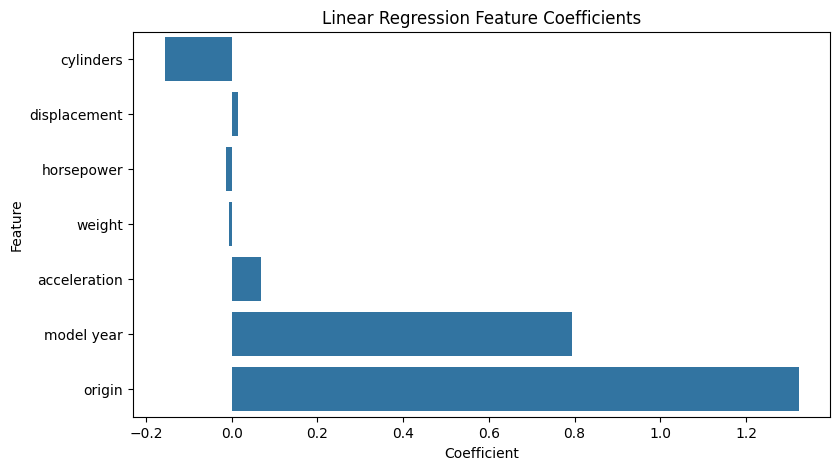

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()

In [ ]:
new_car = pd.DataFrame({
    "cylinders": [4],
    "displacement": [120],
    "horsepower": [90],
    "weight": [2500],
    "acceleration": [16],
    "model year": [80],
    "origin": [1]
})

predicted_mpg = model.predict(new_car)

print(
    f"Predicted Car Mileage: {predicted_mpg[0]:.2f} MPG"
)